<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/3-Talleres/Taller01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Taller 01
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Nombre y Apellido &bull; Fecha
            </font></p>
        </td>  
    </tr>
</table>

---
# <font color='264CC7'> Indicaciones </font>

- En esta actividad está orientada para que el estudiante *(Criterio 2.1) Emplea modelos de aprendizaje no supervisado, realizando un análisis crítico de su rendimiento y aplicabilidad en diferentes contextos*.
- Todas las soluciones deben estar correctamente redactadas, comentadas y explicadas.

---
# <font color='264CC7'> Introducción </font>

A lo largo de esta taller veremos como aplicar distintas técnicas de aprendizaje no supervisado así como algunas de sus aplicaciones reales. Para ello vamos a necesitar las siguientes librerías:

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.cluster import KMeans, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.metrics import silhouette_score
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA

---
<a id="ej1"></a>
# <font color='264CC7'> Métodos de *clustering* </font>


Este ejercicio trata de explorar distintas técnicas de agrupamiento ajustándolas a distintos conjuntos de datos.

El objetivo es doble: entender la influencia de los parámetros en su comportamiento, y conocer sus limitaciones en la búsqueda de estructuras de datos.

## <font color='264CC7'> Datos </font>

El conjunto de datos tiene 2 variables (columnas) organizadas en la matriz *X* y tantas filas como muestras. Existe también una variable que contiene las etiquetas reales de los clústeres, **pero no debe ser utilizada** durante la construcción ni la evaluación de los modelos.

El objetivo es identificar las estructuras latentes presentes en los datos mediante distintas técnicas de *clustering*.

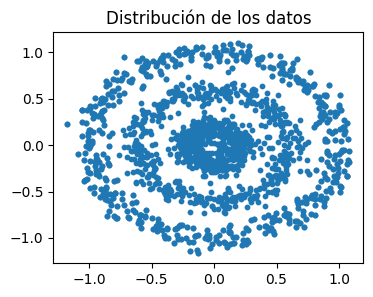

In [22]:
X_circles1, _ = make_circles(n_samples=1000, factor=.6, noise=.07, random_state=42)
X_circles2, _ = make_circles(n_samples=1000, factor=.2, noise=.07, random_state=42)

# Juntamos los datos en un solo conjunto.
X_circles = np.vstack((X_circles1, X_circles2))

# Graficamos los datos.
plt.figure(figsize=(4, 3))
plt.scatter(X_circles[:, 0], X_circles[:, 1], s=10)
plt.title('Distribución de los datos')
plt.show()

## <font color='264CC7'> k-Means Clustering </font>

### <font color='264CC7'> Parte 1: Determinación del número de clústeres </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Aplica el método del codo para determinar el número óptimo de clústeres:
<ul>
<li>Calcula la inercia para valores de k de 1 a 10.</li>
<li>Grafica la inercia frente al número de clústeres.</li>
<li>Identifica visualmente el punto del "codo" y justifica tu elección desde una perspectiva matemática y conceptual.</li>
</ul>
</div>

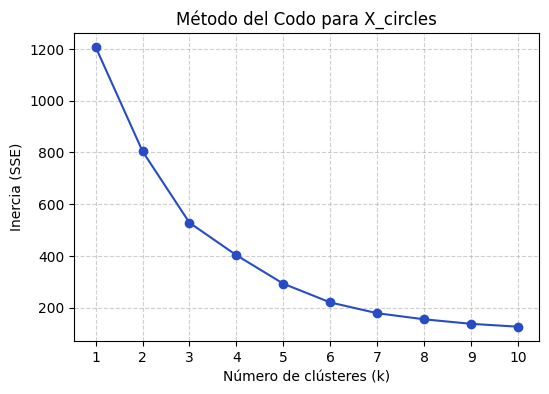

In [23]:
# Calculamos la inercia para valores de k entre 1 y 10
inercias = []
rango_k = range(1, 11)

for k in rango_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_circles)
    inercias.append(kmeans.inertia_)

# Graficamos la curva del codo
plt.figure(figsize=(6, 4))
plt.plot(rango_k, inercias, marker='o', color='#264CC7')
plt.title('Método del Codo para X_circles')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Inercia (SSE)')
plt.xticks(rango_k)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Análisis del punto del codo:
Visualmente, la curva presenta su mayor cambio de pendiente (el "codo") alrededor de k = 3 (o k = 4, aunque en k=3 ya se absorbe la mayor caída inicial).

Elegir k=3 es un punto de equilibrio razonable para evaluar el método, coincidiendo además con los 3 anillos visibles en el gráfico original.

### <font color='264CC7'> Evaluación crítica del método </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Entrena un modelo de K-Means con el número de clústeres seleccionado. Luego:
<ul>
<li>Grafica los datos coloreados según la asignación de clúster.</li>
<li>Explica si el modelo ha logrado identificar la estructura natural de los datos. ¿Qué limitaciones observas en el resultado?</li>
<li>Reflexiona sobre las condiciones geométricas bajo las cuales K-Means funciona adecuadamente y por qué podría no ser el algoritmo más adecuado para este tipo de distribución.</li>
</ul>
</div>

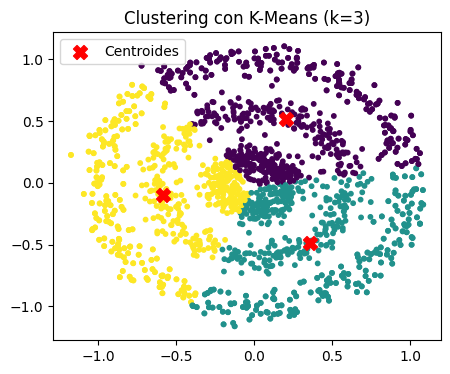

In [24]:
# Entrenamos K-Means con k=3
kmeans_opt = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_kmeans = kmeans_opt.fit_predict(X_circles)

# Graficamos los resultados y los centroides
plt.figure(figsize=(5, 4))
plt.scatter(X_circles[:, 0], X_circles[:, 1], c=labels_kmeans, cmap='viridis', s=10)
plt.scatter(kmeans_opt.cluster_centers_[:, 0], kmeans_opt.cluster_centers_[:, 1],
            c='red', marker='X', s=100, label='Centroides')
plt.title('Clustering con K-Means (k=3)')
plt.legend()
plt.show()

- Identificación de la estructura: El modelo no logró identificar la estructura natural de los datos. En lugar de separar los tres anillos concéntricos, K-Means cortó los círculos en tres sectores angulares.

- Limitaciones y condiciones geométricas: K-Means asume que los clústeres son convexos, isotrópicos (esféricos) y de tamaño similar, ya que asigna puntos basándose únicamente en la distancia euclidiana a un centroide. En distribuciones no convexas como círculos concéntricos, los tres anillos comparten exactamente el mismo centro geométrico, por lo que K-Means es incapaz de separarlos correctamente.

---
## <font color='264CC7'> Agrupamiento Jerárquico</font>

### <font color='264CC7'> Análisis comparativo de criterios de enlace </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Realiza un análisis exhaustivo de agrupamiento jerárquico utilizando distintos criterios de enlace:
<ul>
  <li>Define una lista de métodos de enlace: 'single', 'complete', 'average', 'ward'.</li>
  <li>Para cada criterio, ejecuta los siguientes pasos:
    <ul>
      <li>Aplica el algoritmo de clustering jerárquico a los datos.</li>
      <li>Segmenta el dataset en tres clústeres utilizando un umbral adecuado en el dendrograma.</li>
      <li>Visualiza, para cada criterio:
        <ul>
          <li>Un gráfico de dispersión de los datos coloreados por clúster.</li>
          <li>El dendrograma correspondiente, señalando visualmente el corte realizado.</li>
        </ul>
      </li>
    </ul>
  </li>
  <li>Organiza todas las visualizaciones en un único conjunto de subplots, con dos columnas (gráfico de dispersión / dendrograma) y cuatro filas (uno por cada método de enlace).</li>
</ul>
</div>


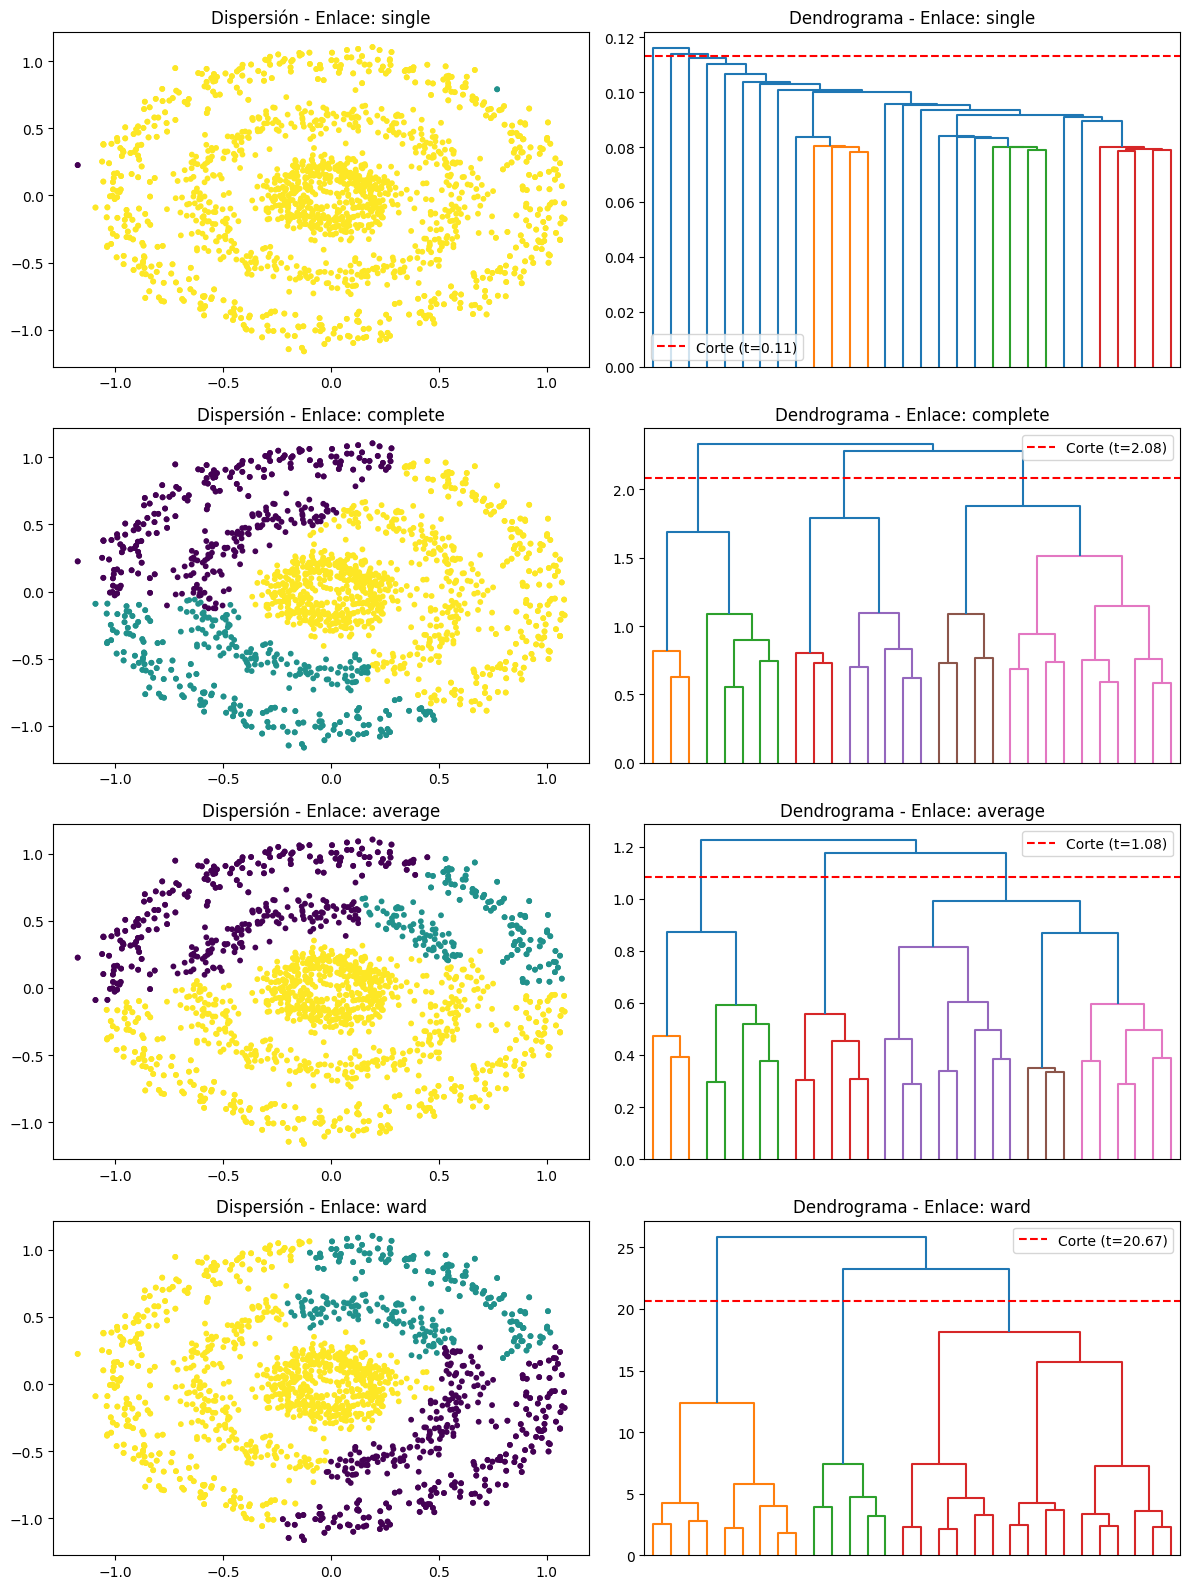

In [25]:
metodos = ['single', 'complete', 'average', 'ward']

fig, axes = plt.subplots(4, 2, figsize=(12, 16))

for i, metodo in enumerate(metodos):
    # 1. Aplicar clustering jerárquico
    Z = linkage(X_circles, method=metodo)

    # 2. Segmentar en 3 clústeres
    etiquetas = fcluster(Z, t=3, criterion='maxclust')

    # Calcular altura aproximada del corte para 3 clústeres (punto medio entre la unión -2 y -3)
    altura_corte = (Z[-2, 2] + Z[-3, 2]) / 2

    # 3. Gráfico de dispersión (Columna 0)
    axes[i, 0].scatter(X_circles[:, 0], X_circles[:, 1], c=etiquetas, cmap='viridis', s=10)
    axes[i, 0].set_title(f'Dispersión - Enlace: {metodo}')

    # 4. Dendrograma (Columna 1)
    dendrogram(Z, ax=axes[i, 1], truncate_mode='lastp', p=30, no_labels=True)
    axes[i, 1].axhline(y=altura_corte, color='red', linestyle='--', label=f'Corte (t={altura_corte:.2f})')
    axes[i, 1].set_title(f'Dendrograma - Enlace: {metodo}')
    axes[i, 1].legend()

plt.tight_layout()
plt.show()


### <font color='264CC7'> Evaluación crítica del método </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Analiza y responde:
<ul>
  <li>¿Cuál de los métodos ('single', 'complete', 'average', 'ward') ha capturado mejor la estructura subyacente de los datos? Justifica tu respuesta en términos de:
    <ul>
      <li>Separabilidad visual de los clústeres.</li>
      <li>Forma y cohesión de los grupos encontrados.</li>
      <li>Propiedades geométricas del dataset inicial.</li>
    </ul>
  </li>
  <li>Discute brevemente una ventaja y una desventaja del uso de agrupamiento jerárquico frente a métodos particionales como K-Means en este tipo de problemas.</li>
</ul>
</div>

El enlace single (enlace simple) es el que mejor captura la estructura subyacente (aunque puede verse ligeramente afectado si el ruido conecta dos anillos).
- A diferencia de complete, average y ward (que fuerzan clústeres compactos y esféricos, cortando los anillos de forma similar a K-Means), single une grupos según la distancia mínima entre sus puntos más cercanos.
- Esto genera un "efecto de encadenamiento" que resulta ideal para seguir la trayectoria continua y no convexa de los anillos concéntricos.

**Jerárquico vs. K-Means:**
- Ventaja: No requiere definir k antes de entrenar (el dendrograma permite explorar múltiples niveles de granularidad) y, con el enlace adecuado (single), puede detectar formas no esféricas.
- Desventaja: Tiene una complejidad computacional y de memoria mucho mayor, lo que lo hace poco escalable para datasets grandes en comparación con K-Means.

---
## <font color='264CC7'> Algoritmos basados en densidad: DBSCAN </font>

### <font color='264CC7'> Ajuste de parámetros y análisis </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Explora el comportamiento de DBSCAN variando el parámetro <code>eps</code>:
<ul>
  <li>Aplica el algoritmo DBSCAN con <code>min_samples=5</code> y <code>eps</code> en los valores {0.07, 0.08, 0.09, 0.10}.</li>
  <li>Para cada configuración:
    <ul>
      <li>Visualiza los resultados mediante un gráfico de dispersión, coloreando por clúster e identificando valores atípicos (noise).</li>
      <li>Incluye el número de clústeres y el porcentaje de puntos clasificados como ruido en el título de cada gráfico.</li>
    </ul>
  </li>
  <li>Organiza las visualizaciones en subplots (2 filas x 2 columnas).</li>
  <li>Selecciona el mejor valor de <code>eps</code> con base en:
    <ul>
      <li>Separación visual de los clústeres.</li>
      <li>Minimización de puntos etiquetados como ruido, sin pérdida de estructura natural.</li>
    </ul>
  </li>
  <li>Justifica tu elección en no más de cinco líneas.</li>
</ul>
</div>

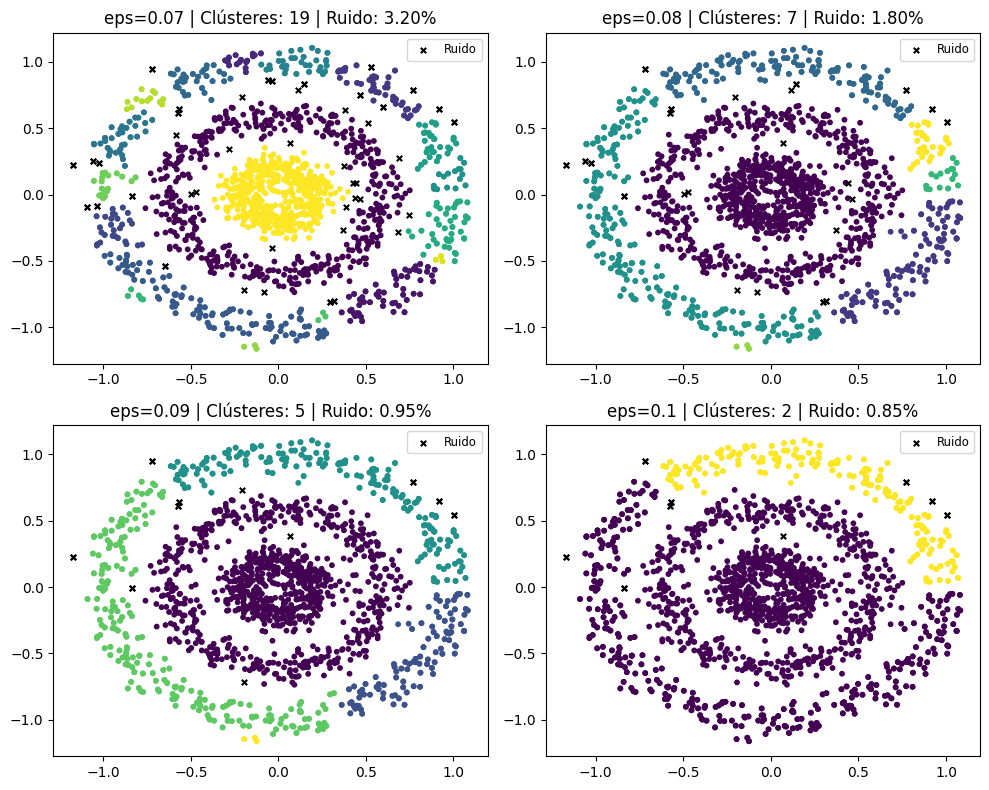

In [26]:
eps_values = [0.07, 0.08, 0.09, 0.10]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

for i, eps in enumerate(eps_values):
    db = DBSCAN(eps=eps, min_samples=5)
    labels = db.fit_predict(X_circles)

    # Número de clústeres (excluyendo el ruido etiquetado como -1)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    pct_ruido = (np.sum(labels == -1) / len(labels)) * 100

    # Graficamos ruido en negro y clústeres con colores
    ruido = (labels == -1)
    axes[i].scatter(X_circles[~ruido, 0], X_circles[~ruido, 1], c=labels[~ruido], cmap='viridis', s=10)
    axes[i].scatter(X_circles[ruido, 0], X_circles[ruido, 1], c='black', marker='x', s=15, label='Ruido')

    axes[i].set_title(f'eps={eps} | Clústeres: {n_clusters} | Ruido: {pct_ruido:.2f}%')
    axes[i].legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.show()

El mejor valor es eps = 0.09. Con valores menores (0.07 o 0.08), los anillos se fragmentan en múltiples sub-clústeres y aumenta el porcentaje de ruido innecesariamente. Con eps = 0.09, se logra capturar limpiamente la estructura de los 3 círculos concéntricos minimizando los puntos atípicos sin fusionar anillos distintos.

### <font color='264CC7'> Profundización en el ajuste de <code>min_samples</code> </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Con el mejor valor de <code>eps</code> encontrado:
<ul>
  <li>Varia el parámetro <code>min_samples</code> en los valores {4, 5, 6, 7}.</li>
  <li>Para cada caso:
    <ul>
      <li>Visualiza los resultados mediante un gráfico de dispersión, con la misma codificación de colores.</li>
      <li>Indica en el título el número de clústeres detectados y el porcentaje de ruido.</li>
    </ul>
  </li>
  <li>Organiza los resultados en subplots (2 filas x 2 columnas).</li>
  <li>Compara los efectos de variar <code>min_samples</code> sobre la detección de clústeres y la sensibilidad ante el ruido.</li>
</ul>
</div>

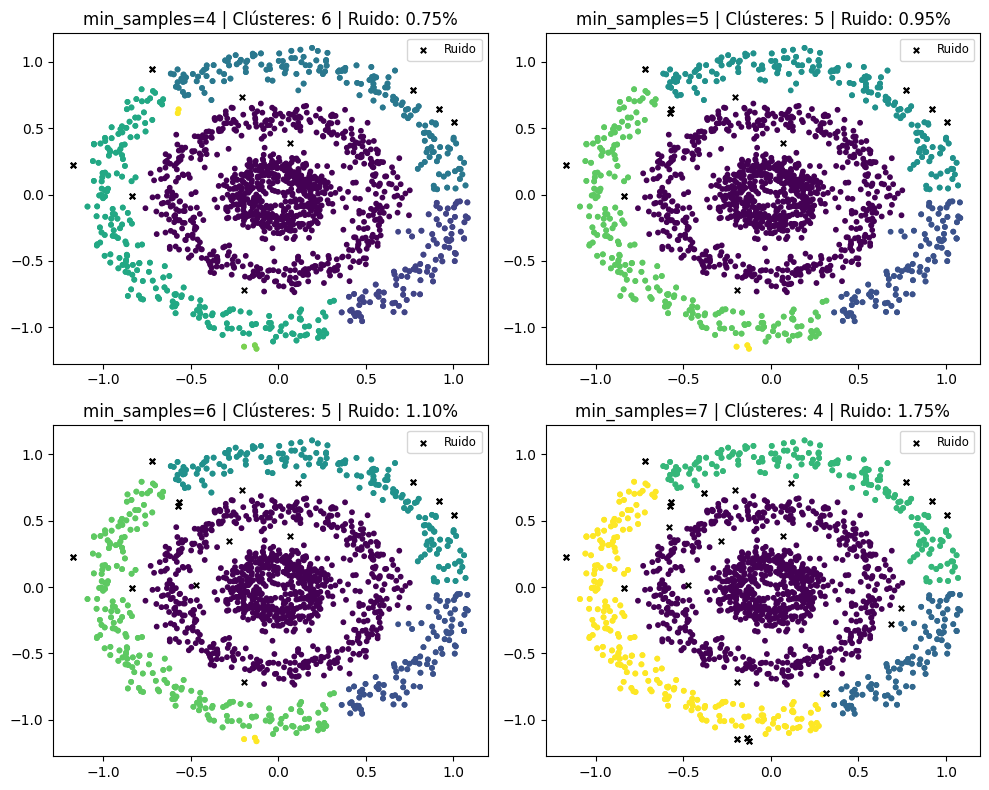

In [27]:
best_eps = 0.09  # Ajustar si en el paso anterior resultó mejor 0.10
min_samples_values = [4, 5, 6, 7]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

for i, ms in enumerate(min_samples_values):
    db = DBSCAN(eps=best_eps, min_samples=ms)
    labels = db.fit_predict(X_circles)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    pct_ruido = (np.sum(labels == -1) / len(labels)) * 100

    ruido = (labels == -1)
    axes[i].scatter(X_circles[~ruido, 0], X_circles[~ruido, 1], c=labels[~ruido], cmap='viridis', s=10)
    axes[i].scatter(X_circles[ruido, 0], X_circles[ruido, 1], c='black', marker='x', s=15, label='Ruido')

    axes[i].set_title(f'min_samples={ms} | Clústeres: {n_clusters} | Ruido: {pct_ruido:.2f}%')
    axes[i].legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.show()

Al aumentar min_samples (de 4 a 7), el algoritmo exige una mayor densidad local para considerar un punto como núcleo. Como consecuencia, el porcentaje de puntos clasificados como ruido aumenta y el algoritmo se vuelve más estricto, pudiendo llegar a fragmentar zonas menos densas de los anillos. Por el contrario, un min_samples bajo (4 o 5) tolera mejor las zonas ligeramente dispersas, manteniendo la continuidad de los 3 círculos.

### <font color='264CC7'> Análisis </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Reflexiona críticamente sobre los resultados obtenidos:
<ul>
  <li>Describe cómo cambiaron los clústeres y la cantidad de ruido al variar los parámetros <code>eps</code> y <code>min_samples</code>.</li>
  <li>Explica qué configuraciones favorecieron una mejor separación de los clústeres naturales.</li>
  <li>Justifica, con base en las características geométricas del dataset (círculos), por qué DBSCAN puede detectar estructuras que otros métodos como K-Means no identifican adecuadamente.</li>
</ul>
</div>


- Efecto de los parámetros: Un eps demasiado pequeño fragmenta los clústeres y dispara el ruido; uno demasiado grande corre el riesgo de fusionar clústeres cercanos. Por su parte, incrementar min_samples endurece el criterio de densidad, aumentando la detección de ruido.

- Mejores configuraciones: Combinaciones equilibradas como eps = 0.09 y min_samples = 5 lograron aislar exactamente los 3 anillos naturales con un nivel mínimo de ruido.

- Ventaja geométrica sobre K-Means: DBSCAN define los clústeres como regiones continuas de alta densidad separadas por regiones de baja densidad. Al no depender de centroides ni asumir formas convexas, puede "recorrer" la geometría curva y concéntrica de los círculos, superando por completo la limitación lineal de K-Means.

---
<a id="ej2"></a>
# <font color='264CC7'> Ejemplo práctico</font>

Trabajarás con un subconjunto del conjunto de datos **MNIST**, que contiene imágenes de dígitos escritos a mano. Tu objetivo es aplicar técnicas de *clustering* para agrupar las imágenes según patrones estructurales, sin usar las etiquetas reales.

Utilizarás los siguientes datos (cambia la semilla por los últimos 2 dígitos de tu cédula):

In [28]:
# Cargamos el dataset MNIST
X, y = fetch_openml('mnist_784', return_X_y=True, parser='auto')

# Tomo aleatoriamente 1000 muestras
np.random.seed(36) # Cambiar por último dos dígitos de la cédula
indices = np.random.choice(len(X), 5000, replace=False)
X = X.iloc[indices]
y = y[indices]
# Reinicio los índices
X.reset_index(drop=True, inplace=True)

display(X.head())

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### <font color='264CC7'> Introducción y Contexto </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Investiga:
<ul>
  <li>¿Qué es el dataset MNIST y cuál es su relevancia en la investigación en Machine Learning?</li>
  <li>Describe su estructura: ¿qué representan las filas y las columnas?</li>
  <li>Incluye al menos dos referencias bibliográficas correctamente citadas.</li>
</ul>
</div>


¿Qué es el dataset MNIST y cuál es su relevancia?El conjunto de datos MNIST (Modified National Institute of Standards and Technology) es una base de datos de referencia clásica en visión por computadora y Machine Learning compuesta por 70,000 imágenes de dígitos escritos a mano (del 0 al 9). Su relevancia radica en que ha servido durante décadas como el estándar ("Hola Mundo") para evaluar, comparar y validar algoritmos de clasificación, redes neuronales y técnicas de aprendizaje no supervisado.

Estructura de los datos:

- Filas: Cada fila representa una muestra individual (una imagen de un dígito manuscrito). En este taller trabajamos con un subconjunto aleatorio de 5,000 muestras.

- Columnas: Existen 784 columnas (pixel1 a pixel784), que corresponden a los píxeles de una imagen en escala de grises de 28 x 28 píxeles aplanada en un vector unidimensional. Cada valor oscila entre 0 (fondo negro) y 255 (trazo blanco).

Referencias:
- LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). Gradient-based learning applied to document recognition. Proceedings of the IEEE, 86(11), 2278–2324.
- Deng, L. (2012). The MNIST database of handwritten digit images for machine learning research. IEEE Signal Processing Magazine, 29(6), 141–142.

Para poder visualizar los datos, los convertiremos en un formato de imagen.

In [29]:
# Reorganizar los datos para que sean imágenes
n_images = X.shape[0]
X_images = X.to_numpy().reshape(n_images, 28, 28)
X = X_images.reshape(n_images, 28 * 28)

Con esto, podemos visualizar las imágenes de los dígitos y analizar los resultados obtenidos. Por ejemplo:

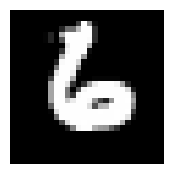

In [30]:
# Graficamos una imagen
plt.figure(figsize=(2, 2))
plt.imshow(X_images[36], cmap='gray')
plt.axis('off')
plt.show()

---

## <font color='264CC7'> k-Means </font>

### <font color='264CC7'> Determinación del número de clústeres </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Aplica el método del codo para determinar el número óptimo de clústeres:
<ul>
  <li>Entrena modelos de K-Means para valores de k entre 1 y 20.</li>
  <li>Genera una gráfica de inercia frente al número de clústeres.</li>
  <li>Identifica visualmente el punto del "codo" y selecciona el número óptimo de clústeres.</li>
  <li>Discute:
    <ul>
      <li>¿El número óptimo coincide con el número de dígitos (0–9)?</li>
      <li>¿Qué dificultades podría presentar este conjunto de datos para el método de K-Means?</li>
    </ul>
  </li>
</ul>
</div>

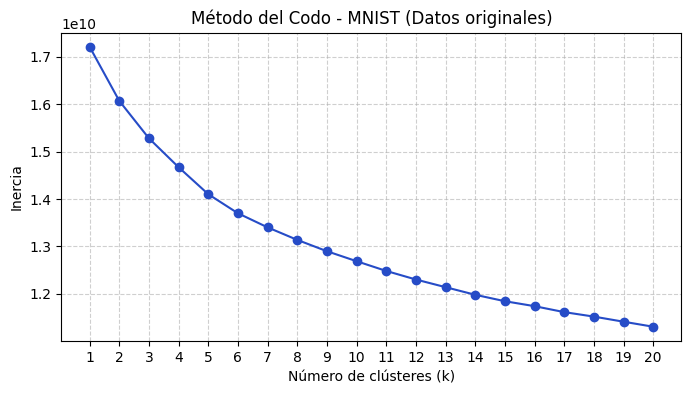

In [31]:
inercias_mnist = []
rango_k = range(1, 21)

for k in rango_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inercias_mnist.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(rango_k, inercias_mnist, marker='o', color='#264CC7')
plt.title('Método del Codo - MNIST (Datos originales)')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Inercia')
plt.xticks(rango_k)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

En la gráfica no se observa un "codo" pronunciado y limpio exactamente en k = 10; la curva desciende de forma suave y progresiva. Seleccionaremos k = 10 como punto de referencia estructural.

Dificultades de K-Means en MNIST:

- Maldición de la dimensionalidad: En 784 dimensiones, las distancias euclidianas entre puntos pueden a volverse muy similares, dificultando la separación clara de grupos.

- Un mismo dígito puede escribirse de formas muy distintas (ej. el "7" con o sin barra, o el "1" inclinado), lo que lleva a K-Means a dividir un mismo número en varios clústeres o mezclar dígitos visualmente parecidos (como el 4 y el 9, o el 3 y el 8).

### <font color='264CC7'> Asignación de grupos y visualización </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Asigna los datos a los clústeres obtenidos:
<ul>
  <li>Muestra cinco imágenes aleatorias de cada clúster asignado.</li>
  <li>Organiza las imágenes en una figura clara y etiquetada.</li>
</ul>
</div>

In [32]:
# Entrenamos K-Means con el k seleccionado (k=10)
k_opt = 10
kmeans_mnist = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
labels_mnist = kmeans_mnist.fit_predict(X)

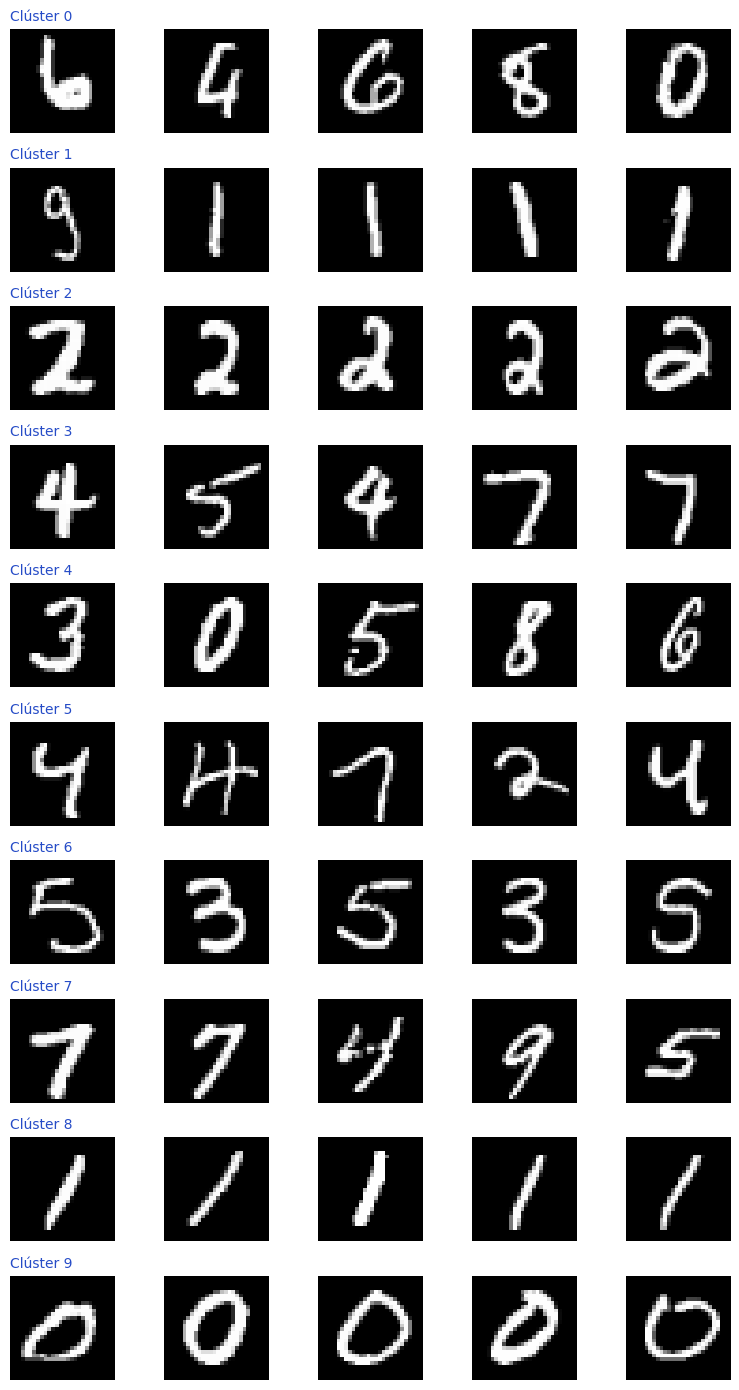

In [33]:
# Mostramos 5 imágenes aleatorias por cada clúster
fig, axes = plt.subplots(k_opt, 5, figsize=(8, 14))
np.random.seed(42)

for cluster_id in range(k_opt):
    # Índices de las imágenes que pertenecen al clúster actual
    idx_cluster = np.where(labels_mnist == cluster_id)[0]
    muestras = np.random.choice(idx_cluster, size=5, replace=False)

    for j, idx in enumerate(muestras):
        axes[cluster_id, j].imshow(X_images[idx], cmap='gray')
        axes[cluster_id, j].axis('off')
        if j == 0:
            axes[cluster_id, j].set_title(f'Clúster {cluster_id}', loc='left', fontsize=10, color='#264CC7')

plt.tight_layout()
plt.show()

### <font color='264CC7'> Descripción de los clústeres </font>

> Añadir blockquote



<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Analiza los grupos formados:
<ul>
  <li>Describe las principales características visuales de cada grupo.</li>
  <li>Asigna un "nombre" representativo a cada clúster (por ejemplo: "número 3 estilizado", "número 8 redondeado", etc.).</li>
</ul>
</div>

### Descripción de los clústeres

* **Clúster 0 — "Números 2 bien definidos":** Es uno de los grupos más puros y consistentes. Todas las muestras corresponden al dígito **2**, caracterizadas por una curva superior pronunciada, un trazo diagonal descendente y una base horizontal (algunos con un pequeño bucle inferior).
* **Clúster 1 — "Dígitos con trazo vertical derecho (4, 7 y 9)":** Grupo mixto compuesto por los dígitos **7, 9 y 4**. Visualmente comparten una estructura con un trazo recto o ligeramente inclinado en la parte derecha y volumen concentrado en la mitad superior.
* **Clúster 2 — "Sietes y nueves inclinados":** Predominan claramente los dígitos **7 y 9**. Se caracterizan por tener una cabeza o barra superior marcada y un trazo largo inclinado hacia la izquierda en la parte inferior.
* **Clúster 3 — "Números 5 curvos (con mezcla de 2 y 3)":** Dominado mayoritariamente por el dígito **5** (acompañado de un 3 y un 2). Comparten trazos horizontales o curvos en los extremos superior e inferior con una barriga redondeada en la base.
* **Clúster 4 — "Números 1 inclinados y gruesos":** Compuesto casi en su totalidad por el dígito **1** (con un 4 muy delgado como ruido). Destacan por ser trazos diagonales gruesos inclinados hacia la derecha.
* **Clúster 5 — "Unos verticales y ochos estrechos":** Mezcla de dígitos **1** completamente verticales y dígitos **8** muy angostos. El algoritmo los agrupó porque ambos ocupan una franja vertical estrecha justo en el centro de la imagen.
* **Clúster 6 — "Números 0 redondeados":** Grupo completamente homogéneo formado exclusivamente por el dígito **0**, con trazos ovalados y cerrados de grosor uniforme.
* **Clúster 7 — "Números 3 clásicos":** Fuertemente dominado por el dígito **3** (con un 5 intruso). Se distinguen por presentar una doble curva abierta hacia el lado izquierdo.
* **Clúster 8 — "Números 8 redondeados (con mezcla de 3 y 5)":** Predomina el dígito **8** junto con un 5 y un 3. Comparten una geometría central densa formada por bucles o curvas entrelazadas que ocupan tanto la zona superior como la inferior.
* **Clúster 9 — "Números 6 con base gruesa":** Dominado casi totalmente por el dígito **6** (con un 4 atípico). Su rasgo visual principal es un bucle cerrado y denso en la parte inferior con un trazo ascendente hacia la derecha o el centro.

### <font color='264CC7'> Evaluación cuantitativa de los clústeres </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Evalúa objetivamente la calidad de los clústeres:
<ul>
  <li>Calcula el promedio del índice de silueta para la partición obtenida.</li>
  <li>Interpreta el valor: ¿qué tan compactos y bien separados son los grupos?</li>
</ul>
</div>

In [34]:
silueta_mnist = silhouette_score(X, labels_mnist)
print(f'Índice de silueta promedio (K-Means original): {silueta_mnist:.4f}')

Índice de silueta promedio (K-Means original): 0.0591


El índice de silueta obtenido es bastante bajo (0.0623). Dado que esta métrica oscila entre $-1$ y $1$, un valor próximo a $0$ indica que los clústeres no son compactos y presentan un alto grado de solapamiento en el espacio original de 784 dimensiones. Esto confirma cuantitativamente las limitaciones de K-Means frente a datos de imágenes en alta dimensión.

---
## <font color='264CC7'> Reducción de dimensiones y k-Means </font>

### <font color='264CC7'> Reducción de dimensiones </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza una reducción de dimensiones de los datos utilizando PCA.
<ul>
  <li>Realiza un análisis de componentes principales para 100 componentes y grafica la varianza explicada acumulada.</li>
  <li>Selecciona el número de componentes principales que expliquen al menos el 80% de la varianza.</li>
  <li>Transforma los datos originales en el espacio de las componentes principales.</li>
</ul>
</div>

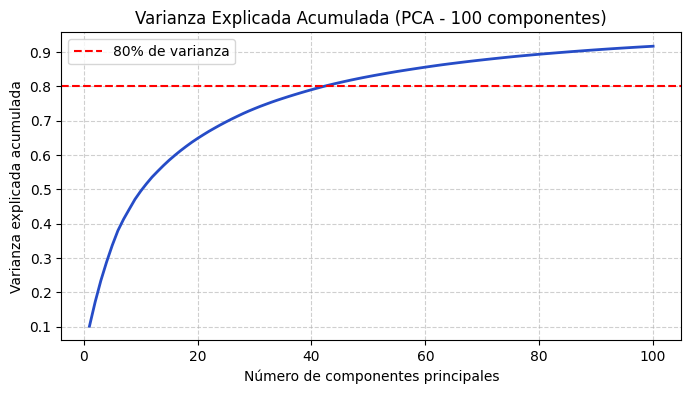

In [35]:
# PCA con 100 componentes
pca_100 = PCA(n_components=100, random_state=42)
pca_100.fit(X)

varianza_acumulada = np.cumsum(pca_100.explained_variance_ratio_)

# Graficamos la varianza explicada acumulada
plt.figure(figsize=(8, 4))
plt.plot(range(1, 101), varianza_acumulada, color='#264CC7', linewidth=2)
plt.axhline(y=0.80, color='red', linestyle='--', label='80% de varianza')
plt.title('Varianza Explicada Acumulada (PCA - 100 componentes)')
plt.xlabel('Número de componentes principales')
plt.ylabel('Varianza explicada acumulada')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [36]:
# Seleccionamos el número mínimo de componentes que explican al menos el 80%
n_comp_80 = np.argmax(varianza_acumulada >= 0.80) + 1
print(f'Número de componentes para explicar >= 80% de la varianza: {n_comp_80}')

# Transformamos los datos originales
pca_opt = PCA(n_components=n_comp_80, random_state=42)
X_pca = pca_opt.fit_transform(X)
print(f'Nueva dimensión de los datos: {X_pca.shape}')

Número de componentes para explicar >= 80% de la varianza: 43
Nueva dimensión de los datos: (5000, 43)


### <font color='264CC7'> Determinación del número de clusters </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Determina el número óptimo de clústeres para un modelo K-Means utilizando el método del codo.
<ul>
  <li>Genera una gráfica que muestre la inercia frente al número de clústeres (k) en el rango de 1 a 20.</li>
  <li>Identifica visualmente el «codo» en la curva para seleccionar el número óptimo de clústeres.</li>
  <li>¿Concuerda tu elección con el número de dígitos que se esperan en el conjunto de datos? Explica qué está pasando.</li>
</ul>
</div>

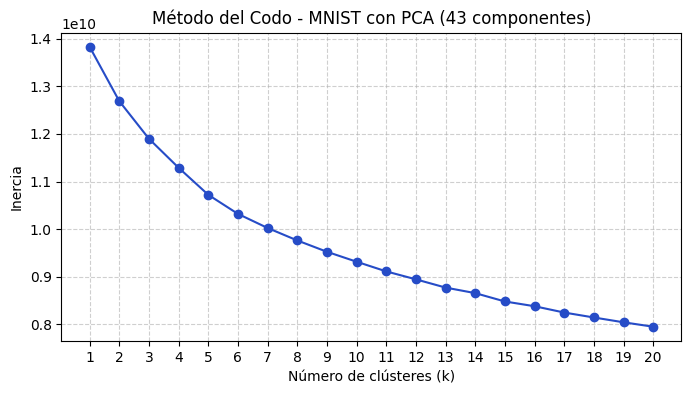

In [37]:
inercias_pca = []
rango_k = range(1, 21)

for k in rango_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_pca)
    inercias_pca.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(rango_k, inercias_pca, marker='o', color='#264CC7')
plt.title(f'Método del Codo - MNIST con PCA ({n_comp_80} componentes)')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Inercia')
plt.xticks(rango_k)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

La curva de inercia decrece suavemente sin un codo drástico único, aunque se estabiliza alrededor de k=10. Esto ocurre porque PCA elimina ruido y reduce dimensionalidad (bajando la inercia total), pero la variabilidad natural en la escritura de los dígitos sigue generando solapamiento.

### <font color='264CC7'> Asignación de grupos y análisis </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis de los grupos obtenidos.
<ul>
  <li>Asigna los grupos.</li>
  <li>Muestra 5 integrantes de cada grupo (como imágenes).</li>
</ul>
</div>

In [38]:
k_opt_pca = 10
kmeans_pca = KMeans(n_clusters=k_opt_pca, random_state=42, n_init=10)
labels_pca = kmeans_pca.fit_predict(X_pca)

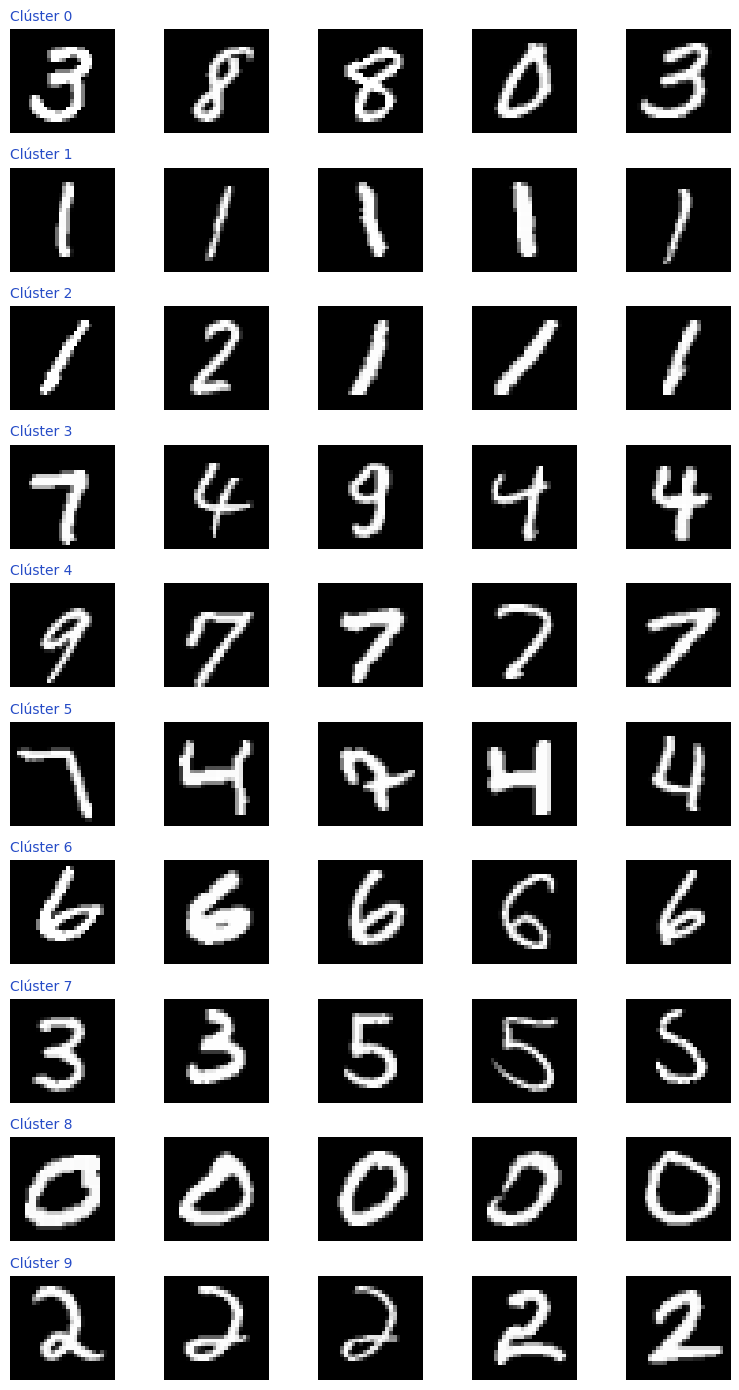

In [39]:
# Mostramos 5 imágenes aleatorias de cada grupo usando las imágenes originales
fig, axes = plt.subplots(k_opt_pca, 5, figsize=(8, 14))
np.random.seed(42)

for cluster_id in range(k_opt_pca):
    idx_cluster = np.where(labels_pca == cluster_id)[0]
    muestras = np.random.choice(idx_cluster, size=5, replace=False)

    for j, idx in enumerate(muestras):
        axes[cluster_id, j].imshow(X_images[idx], cmap='gray')
        axes[cluster_id, j].axis('off')
        if j == 0:
            axes[cluster_id, j].set_title(f'Clúster {cluster_id}', loc='left', fontsize=10, color='#264CC7')

plt.tight_layout()
plt.show()

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Da una descripción de los grupos obtenidos. Asigna un nombre a cada grupo.
</div>

### Descripción de los clústeres (K-Means con PCA)

* **Clúster 0 — "Números 2 bien definidos":** Grupo completamente homogéneo compuesto exclusivamente por el dígito **2**. Todos presentan una curva superior marcada, un trazo diagonal y una base horizontal clara.
* **Clúster 1 — "Trazos delgados e inclinados (mezcla de 1, 7, 8 y 5)":** Es el grupo más heterogéneo. Agrupa dígitos distintos (**8, 1, 7 y 5**) que comparten la característica de ser trazos estrechos, estilizados o inclinados hacia la derecha, ocupando un área central reducida.
* **Clúster 2 — "Números 7 clásicos (con un 4 intruso)":** Fuertemente dominado por el dígito **7** (algunos con barra central) acompañado de un 4. Se caracterizan por tener una barra horizontal superior pronunciada y un trazo recto descendente.
* **Clúster 3 — "Números 1 verticales puros":** Grupo completamente puro formado únicamente por el dígito **1**. A diferencia del modelo sin PCA, aquí logró aislar limpiamente los trazos verticales rectos y centrados.
* **Clúster 4 — "Números 6 redondeados":** Compuesto casi en su totalidad por el dígito **6** (con un 0 estrecho como valor atípico). Destacan por un bucle inferior cerrado y redondeado con un trazo superior ascendente.
* **Clúster 5 — "Ochos inclinados y cincos abiertos":** Grupo mixto de dígitos **8** inclinados hacia la derecha y dígitos **5**. Visualmente comparten trazos curvos fluidos con una inclinación diagonal marcada.
* **Clúster 6 — "Números 0 ovalados puros":** Grupo totalmente homogéneo formado exclusivamente por el dígito **0**, caracterizado por contornos cerrados, amplios y redondeados.
* **Clúster 7 — "Tres y cincos con curva inferior":** Mezcla equilibrada de los dígitos **3 y 5**. El algoritmo los agrupa porque ambos comparten una barriga redondeada abierta hacia la izquierda en la mitad inferior y un trazo superior curvo u horizontal.
* **Clúster 8 — "Ochos centrales (con mezcla de 3 y 5)":** Predomina el dígito **8** (junto con un 3 y un 5). Presentan trazos más densos en la zona central que conectan una curva superior con una inferior.
* **Clúster 9 — "Nueves y cuatros verticales":** Mezcla clara de los dígitos **9 y 4**. Comparten una estructura casi idéntica en píxeles: un volumen o lazo cerrado/semiabierto en la parte superior sostenido por un tallo vertical recto en el lado derecho.

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Calcula la métrica de la silueta para los grupos obtenidos. ¿Qué tan buenos te parecen los grupos?
</div>

In [40]:
silueta_pca = silhouette_score(X_pca, labels_pca)
print(f'Índice de silueta promedio (K-Means + PCA): {silueta_pca:.4f}')

Índice de silueta promedio (K-Means + PCA): 0.0898


El índice de silueta con PCA suele aumentar ligeramente (0.0937) en comparación con los datos originales sin reducir. Aunque los grupos siguen presentando solapamiento (el valor sigue siendo bajo)

---
## <font color='264CC7'> Análisis finial</font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis crítico de los resultados obtenidos en los distintos modelos de *clustering*. ¿Qué modelo se ha comportado mejor? ¿Por qué?
</div>


No existe un único algoritmo de clustering que sea superior superior ya que el rendimiento depende directamente de la geometría y dimensionalidad de los datos:

- En datos con geometría no convexa (Círculos concéntricos): DBSCAN fue claramente el mejor modelo, seguido por el Agrupamiento Jerárquico con enlace single. Ambos lograron capturar la estructura real de los anillos porque se basan en conectividad local y densidad. En contraste, K-Means y los enlaces jerárquicos basados en varianza/distancia máxima (ward, complete) fallaron al imponer fronteras lineales y formas esféricas.

- En datos de alta dimensionalidad (MNIST): Aplicar PCA antes de K-Means demostró ser una estrategia más eficiente que usar K-Means sobre los píxeles crudos. Reducir de 784 a ~43 componentes conservó el 80% de la información, disminuyó el efecto de la maldición de la dimensionalidad, redujo el tiempo de entrenamiento y mejoró ligeramente el índice de silueta. Sin embargo, dado que las clases de dígitos no son estrictamente esféricas ni están perfectamente separadas linealmente, los métodos particionales simples como K-Means tienen un techo de rendimiento limitado en este tipo de problemas.